# Greenland Ice Velocity comparison tutorial (Saqqap Sermia and Kangaasarsuup Sermia)

The PROMICE Ice Velocity product is a time-series of Greenland Ice Sheet velocity mosaics based on ESA Sentinel-1 SAR offset tracking (spatial resolution: 200 m). A new mosaic spanning 2 Sentinel-1A/-1B/-1C cycles is posted every 12 days, with each new mosaic supplied as a NetCDF file. The data product is described in detail in [Solgaard et al. (2021)](https://doi.org/10.5194/essd-13-3491-2021). We aim to make each new mosaic available within 10 days of the last included acquisition.

Here, we will look at how to query and fetch the dataset from our [Thredds server](https://thredds.geus.dk/), which is where we store and operationally update the PROMICE Ice Velocity product. Specifically, we will compare ice velocities at two land-terminating glaciers near Nuuk in Southwest Greenland to demonstrate how to:
1. Access remote ice velocity datasets via THREDDS
2. Visualise and compare ice velocity fields using geospatial maps
3. Compute flowline-based velocity statistics
4. Plot and compare ice velocities from two flowlines

Firstly, let's import the packages that we will need.

In [1]:
# Core libraries
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# Data access
from siphon.catalog import TDSCatalog

# Time and utilities
from datetime import datetime
import re

# Mapping
import cartopy.crs as ccrs
import cartopy.feature as cfeature

## 1. Access remote ice velocity datasets via THREDDS
To begin with, we will fetch the ice velocity dataset for a specific timeframe at our region of interest. We will do this via the [GEUS Thredds server](https://thredds.geus.dk/), where the ice velocity dataset is hosted as a series of individual files representing each time step.

Firstly we will define our timeframe and the two regions of interest around Saqqap Sermia (also known as Qimerlugussuaq) and Kangaasarsuup Sermia. This information regarding time and space will compose our query for extracting what we need from the ice velocity dataset.

In [3]:
# Time range
start = datetime(2017, 5, 1)
end = datetime(2025, 10, 1)

# ROI (region of interest) 1: Saqqap Sermia
x1, x2 = -280000, -237500
y1, y2 = -2690000, -2725000

# ROI 2: Kangaasarsuup Sermia
x3, x4 = -250000, -210000
y3, y4 = -2820000, -2856000

# Combined bounds
x_min = min(x1,x2,x3,x4)
x_max = max(x1,x2,x3,x4)
y_min = min(y1,y2,y3,y4)
y_max = max(y1,y2,y3,y4)

print(f"Time frame: {start}, {end}")
print(f"Spatial bounds for both glacier catchment ROIs: {x_min}, {x_max}, {y_min}, {y_max}")

Time frame: 2017-05-01 00:00:00, 2025-10-01 00:00:00
Spatial bounds for both glacier catchment ROIs: -280000, -210000, -2856000, -2690000


These are two land-terminating glaciers that are situated approximately 100 km away from each other. Therefore, instead of querying the dataset over two discrete regions, we have combined them in order to fetch the dataset more efficiently across one region of interest that contains both glacier catchments.

Now let's connect and fetch all files URLs that coincide with our defined timeframe.

In [5]:
catalog_url = "https://thredds.geus.dk/thredds/catalog/IVdata/rotr/catalog.xml"
cat = TDSCatalog(catalog_url)

urls = [ds.access_urls["OPENDAP"] for ds in cat.datasets.values() if "OPENDAP" in ds.access_urls]

def extract_date_range(url):
    m = re.search(r'(\d{8})_(\d{8})\.nc$', url)
    if m:
        return datetime.strptime(m.group(1), "%Y%m%d"), datetime.strptime(m.group(2), "%Y%m%d")
    return None, None

filtered_urls = []
for url in urls:
    s, e = extract_date_range(url)
    if s and e and e >= start and s <= end:
        filtered_urls.append(url)

print(f"Using {len(filtered_urls)} files")
print(f"List of last 5 file URLs: {filtered_urls[-5:]}")

Using 258 files
List of last 5 file URLs: ['https://thredds.geus.dk/thredds/dodsC/IVdata/rotr/IV_ROTR_V5_20250808_20250901.nc', 'https://thredds.geus.dk/thredds/dodsC/IVdata/rotr/IV_ROTR_V5_20250820_20250913.nc', 'https://thredds.geus.dk/thredds/dodsC/IVdata/rotr/IV_ROTR_V5_20250901_20250925.nc', 'https://thredds.geus.dk/thredds/dodsC/IVdata/rotr/IV_ROTR_V5_20250913_20251007.nc', 'https://thredds.geus.dk/thredds/dodsC/IVdata/rotr/IV_ROTR_V5_20250925_20251019.nc']


We now have a list of file URLs, which we will open and query with xarray. We will extract the variables that we want in our ROI, and then combine them all.

Large queries over multiple time steps and big regions can often be costly in time and resources, so be wary of how many files you are working from and how large your region is.

Let's download the horizontal surface velocity magnitude variable, and the corresponding standard deviation variable, and subset them to our region of interest. Then, we can combine them all along their corresponding coordinates, and produce an average of all time steps

In [6]:
datasets = []

for url in filtered_urls:
    print(f"Loading {url}...")
    try:
        ds = xr.open_dataset(url)

        subset = ds[["land_ice_surface_velocity_magnitude", "land_ice_surface_velocity_magnitude_std"]].sel(
            x=slice(x_min, x_max),
            y=slice(y_max, y_min)
        ).load()

        datasets.append(subset)
        ds.close()

    except Exception as e:
        print("Skipping:", e)

ds_combined = xr.combine_by_coords(datasets, combine_attrs="override")

Loading https://thredds.geus.dk/thredds/dodsC/IVdata/rotr/IV_ROTR_V5_20170416_20170509.nc...
Loading https://thredds.geus.dk/thredds/dodsC/IVdata/rotr/IV_ROTR_V5_20170428_20170522.nc...
Loading https://thredds.geus.dk/thredds/dodsC/IVdata/rotr/IV_ROTR_V5_20170510_20170603.nc...
Loading https://thredds.geus.dk/thredds/dodsC/IVdata/rotr/IV_ROTR_V5_20170522_20170615.nc...
Loading https://thredds.geus.dk/thredds/dodsC/IVdata/rotr/IV_ROTR_V5_20170603_20170627.nc...
Loading https://thredds.geus.dk/thredds/dodsC/IVdata/rotr/IV_ROTR_V5_20170615_20170709.nc...
Loading https://thredds.geus.dk/thredds/dodsC/IVdata/rotr/IV_ROTR_V5_20170627_20170721.nc...
Loading https://thredds.geus.dk/thredds/dodsC/IVdata/rotr/IV_ROTR_V5_20170709_20170802.nc...
Loading https://thredds.geus.dk/thredds/dodsC/IVdata/rotr/IV_ROTR_V5_20170721_20170814.nc...
Loading https://thredds.geus.dk/thredds/dodsC/IVdata/rotr/IV_ROTR_V5_20170802_20170826.nc...
Loading https://thredds.geus.dk/thredds/dodsC/IVdata/rotr/IV_ROTR_V5_2

## 2. Visualise and compare ice velocity fields using geospatial maps
To check the dataset we have combined, we can visualise the horizontal surface velocity magnitude and standard deviation by selecting the appropriate variable and plotting it. Let's create two subplots of our region, plotting the mean velocity magnitude and standard deviation from all time steps. We can improve our plots by adding land and ice margin delineations, and overlaying our ice velocities, to better show the setting of these glaciers. We will do this using a package called cartopy, which includes coastline and ice margin delineations.

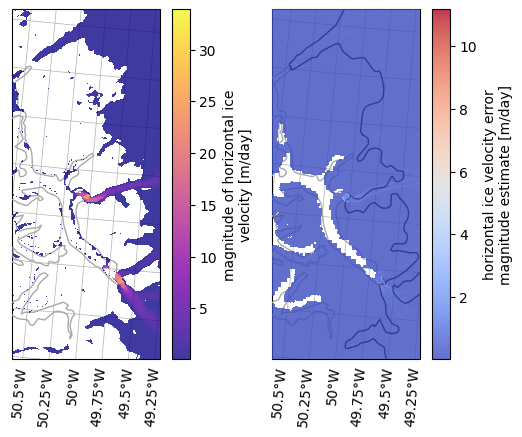

In [9]:
# Compute average horizontal velocity magnitude and std
region_mean = ds_combined["land_ice_surface_velocity_magnitude"].mean(dim="time")
region_std = ds_combined["land_ice_surface_velocity_magnitude_std"].mean(dim="time")

# Mask out slow moving regions (< 0.05 m/day)
region_mean_msk = region_mean.where(region_mean >= 0.05)

# Define map layers
land = cfeature.NaturalEarthFeature(
    category='physical',
    name='land',
    scale='10m',
    edgecolor='darkgray',
    linewidth=1,
    facecolor='none'
)
ice = cfeature.NaturalEarthFeature(
    category='physical',
    name='glaciated_areas',
    scale='10m',        #10m, 50m or 110m
    edgecolor='black',
    linewidth=1,
    facecolor='none'
)

# Define projection
data_crs = ccrs.NorthPolarStereo(central_longitude=-45,
                                 true_scale_latitude=70.5)

# Plot base map layers
fig = plt.figure(figsize=(5,7))
ax1 = fig.add_axes([0.03, 0.49, 0.5, 0.5],
                   projection=data_crs)
ax1.set_extent([x_min,x_max,y_min,y_max],
               crs=data_crs)
ax1.add_feature(land, zorder=10)

ax2 = fig.add_axes([0.55, 0.49, 0.5, 0.5],
                   projection=data_crs)
ax2.set_extent([x_min,x_max,y_min,y_max],
               crs=data_crs)
ax2.add_feature(land, zorder=10)
ax2.add_feature(ice, zorder=11)

# Plot gridlines
gl1 = ax1.gridlines(draw_labels=True)
gl1.top_labels = False
gl2 = ax2.gridlines(draw_labels=True)
gl2.top_labels = False

# Plot regional mean velocity
region_mean_msk.plot(ax=ax1,
                    transform=data_crs,
                    cmap="plasma",
                    alpha=0.8,
                    zorder=20)

# Plot regional std
region_std.plot(ax=ax2,
                transform=data_crs,
                cmap="coolwarm",
                alpha=0.8,
                zorder=20)

# Show plot
plt.show()

From these plots, we can inspect an overview of our region of interest. However, we cannot discern insights into ice dynamics from our two glacier catchments. In order to do so, we could make a subplot with a better focus on our two glacier catchments. Let's clip the dataset to our two regions of interest and visualise these side-by-side.

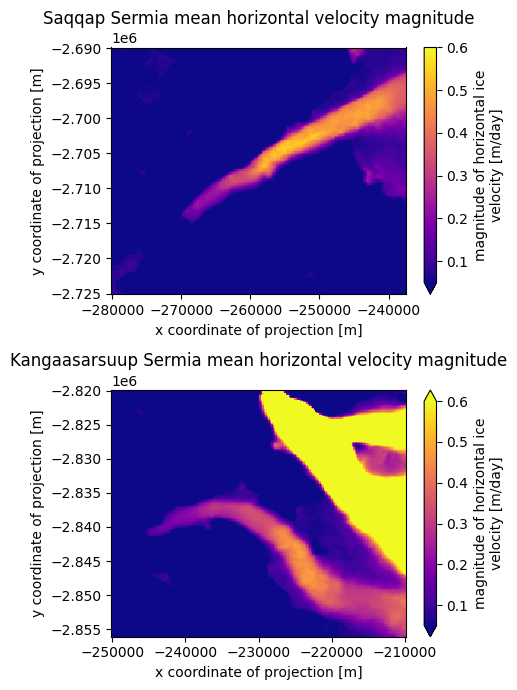

In [32]:
# Subset masked mean velocity mosaic to glacier catchments
saqqap_average = region_mean.sel(
            x=slice(x1, x2),
            y=slice(y1, y2)
)
kangaasarsuup_average = region_mean.sel(
            x=slice(x3, x4),
            y=slice(y3, y4)
)

# Plot mean velocities
fig, (ax1, ax2) = plt.subplots(2,
                               1,
                               figsize=(5,7))

saqqap_average.plot(ax=ax1,
                    cmap="plasma",
                    vmin=0.05,
                    vmax=0.6)

kangaasarsuup_average.plot(ax=ax2,
                        cmap="plasma",
                        vmin=0.05,
                        vmax=0.6)

# Set plot titles and ensure correct spacing
ax1.set_title("Saqqap Sermia mean horizontal velocity magnitude")
ax2.set_title("Kangaasarsuup Sermia mean horizontal velocity magnitude")
plt.tight_layout()

# Show plot
plt.show()

Now we can see spatial patterns in the mean horizontal velocity magnitude much more clearly for each glacier catchment. Saqqap Sermia is a long and narrow tongue extending from the ice sheet, with some faster flowing sections (yellow regions flowing >= 0.6 m/day). Kangaasarssup Sermia is similarly a long and narrow tongue outlet, but flows around a bend (due to topography). Some of the larger mean velocities (green; 0.3 to 0.5 m/day) are apparent along this bend, which indicates steeper topography or higher bed lubrication in this section.

A markedly faster-flowing marine-terminating glacier is next to Kangaasarssup Sermia (yellow, >= 0.6 m/day). This glacier is named Kangiata Nunaata Sermia (KNS), which is the largest outlet glacier in Southwest Greenland and drains approximately 2% of the ice sheet. The contrast in mean horizontal velocity magnitude demonstrates how marine-terminating outlets of the Greenland Ice Sheet are generally much faster flowing than land-terminating outlets. This is mainly because the presence of ocean water introduces an additional source of submarine melting, thinning at the ice bed, and a reduction of basal friction.

Next, let's look at the evolution of spatial patterns in ice velocity across a single year. Let's select the year 2025 and plot averages for every 3 months for each glacier catchment.

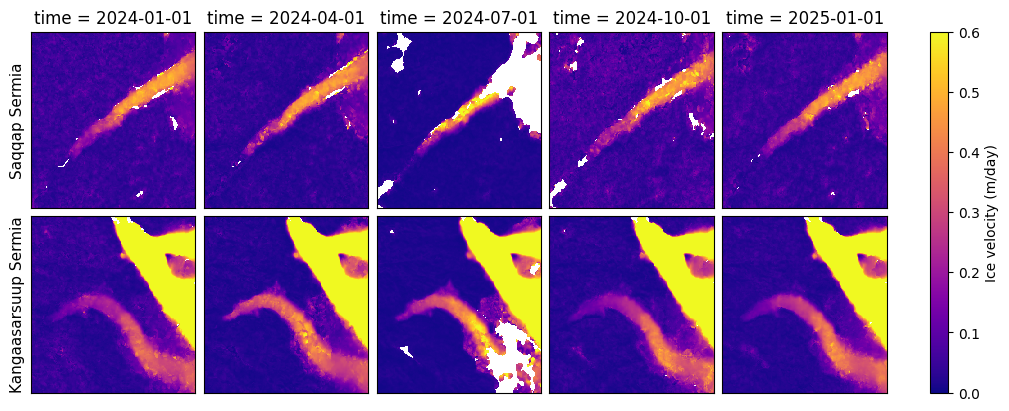

In [46]:
# Resample dataset array as 3-month averages
monthly_mean = (
    ds_combined["land_ice_surface_velocity_magnitude"]
    .resample(time="3MS")
    .mean()
)

# Define months to plot
# print(monthly_mean.time.values)
plotting_months = [
    "2024-01-01",
    "2024-04-01",
    "2024-07-01",
    "2024-10-01",
    "2025-01-01",
]

# Create subplot layout
fig, axs = plt.subplots(
    2,
    len(plotting_months),
    figsize=(10, 4),
    constrained_layout=True
)

# Loop through month bins
for i, month in enumerate(plotting_months):

    # Extract monthly mean timestep
    time_step = monthly_mean.sel(time=month)

    # Select and plot Saqqap Sermia
    saqqap_time_step = time_step.sel(
        x=slice(x1, x2),
        y=slice(y1, y2)
    )
    saqqap_time_step.plot(
        ax=axs[0, i],
        cmap="plasma",
        vmin=0,
        vmax=0.6,
        add_colorbar=False
    )

    # Select and plot Kangaarsuup Sermia
    kangaasarsuup_time_step = time_step.sel(
        x=slice(x3, x4),
        y=slice(y3, y4)
    )
    kangaasarsuup_time_step.plot(
        ax=axs[1, i],
        cmap="plasma",
        vmin=0,
        vmax=0.6,
        add_colorbar=False
    )

    # Remove all plot ticks and labels
    for ax in [axs[0, i], axs[1, i]]:
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel("")
        ax.set_ylabel("")

    # Remove redundant plot titles from second row
    for ax in [axs[1, i]]:
        ax.set_title("")

# Add row labels
axs[0, 0].set_ylabel("Saqqap Sermia", fontsize=11)
axs[1, 0].set_ylabel("Kangaasarsuup Sermia", fontsize=11)

# Plot colorbar
cbar = fig.colorbar(
    axs[0, 0].collections[0],
    ax=axs,
    label="Ice velocity (m/day)"
)

# Show plot
plt.show()

From this plot, we can see the change in ice velocities from the two glacier catchments over the course of one year. Typically, we see an increase in horizontal velocity magnitude in the summer months, which corresponds with an increase in surface melt and runoff that routes to the bed and promotes basal sliding.

Note the slower velocities experienced at the lateral margins, versus the faster velocities in the central part of each glacier tongue. This is typical of glacier outlets that are topographically confined, such as these. Flowlines denote the central path of glacier ice flow, in this case capturing the fastest flowing part of the glacier catchments.

Flowlines are good one-dimensional representations of ice flow, which can be analysed as time-series to demonstrate temporal trends in ice dynamics. Next, let's do this here for both glaciers to form a solid comparison of ice velocities over time.


## 3. Compute flowline-based velocity statistics

First, we need to construct our flowline profiles for each glacier catchment. We will make this as a function, as we will need to use this set of routines twice to make the flowline profiles twice, for our two glacier catchments.

In [57]:
 # Define function, with x and y inputs
 # and the number of interpolated points
 # defined as n
 def define_flowline(x, y, n=30):
    d = np.zeros(len(x))
    for i in range(1, len(x)):
        d[i] = d[i-1] + np.hypot(x[i]-x[i-1], y[i]-y[i-1])
    di = np.linspace(0, d[-1], n)
    return np.interp(di, d, x), np.interp(di, d, y)

Let's now use our function, along with a set of predefined points, to extrapolate our flowline point positions. The number of flowline point positions is defined in our function with the input variable "n". In this case, n=30 and therefore we will have 30 point positions per flowline.

In [60]:
# Define Saqqap Sermia/Qimerlugussuaq flowline points
flowline_x1 = np.array([-268967, -267358, -264784,
                        -262982, -260730, -258477,
                        -256868, -254712, -252074,
                        -249500, -246893, -243708  ])
flowline_y1 = np.array([-2713886, -2712309, -2710250,
                        -2709027, -2708319, -2706968,
                        -2705809, -2704168, -2703203,
                        -2701658, -2700243, -2699406 ])

# Define Kangaasarsuup Sermia flowline points
flowline_x2 = np.array([-244995, -243386, -241970,
                        -240136, -237851, -235727,
                        -232928, -230868, -228455,
                        -226811, -225141, -223854,
                        -222020, -220121])
flowline_y2 = np.array([-2840539, -2840088, -2838962,
                        -2838254, -2837707, -2837031,
                        -2837257, -2838254, -2840056,
                        -2841922, -2844979, -2847521,
                        -2848294, -2848808])

# Compute flowlines using our defined function
x_even1, y_even1 = define_flowline(flowline_x1,
                                   flowline_y1)
x_even2, y_even2 = define_flowline(flowline_x2,
                                   flowline_y2)

print(f"Saqqap Sermia flowline: {x_even1}, {y_even1}")
print(f"Kangaasarsuup Sermia flowline: {x_even2}, {y_even2}")

Saqqap Sermia flowline: [-268967.         -268241.06655096 -267515.13310193 -266736.05637043
 -265942.29861972 -265148.54086902 -264329.20723186 -263488.15157892
 -262595.88022594 -261626.20489536 -260663.94917017 -259792.19905659
 -258920.44894301 -258071.77984881 -257247.00808283 -256430.85142635
 -255622.01971861 -254813.18801088 -253876.82246622 -252922.22049081
 -251976.87678724 -251105.35284585 -250233.82890446 -249358.85521875
 -248465.49654153 -247572.1378643  -246657.26285008 -245674.17523338
 -244691.08761669 -243708.        ], [-2713886.         -2713174.50400924 -2712463.00801848 -2711811.49342141
 -2711176.54889589 -2710541.60437036 -2709941.33653971 -2709370.52018925
 -2708905.60888098 -2708600.75535787 -2708279.39295557 -2707756.65243029
 -2707233.91190502 -2706676.11053124 -2706082.00830827 -2705476.27235187
 -2704860.64487859 -2704245.01740531 -2703862.48585288 -2703513.28535771
 -2703144.7034329  -2702621.58591563 -2702098.46839836 -2701581.39092234
 -2701096.50310942

We can plot our flowline point positions over the top of the ice velocity dataset to check locations. We will plot it over the top of our mean dataset for each glacier catchment.

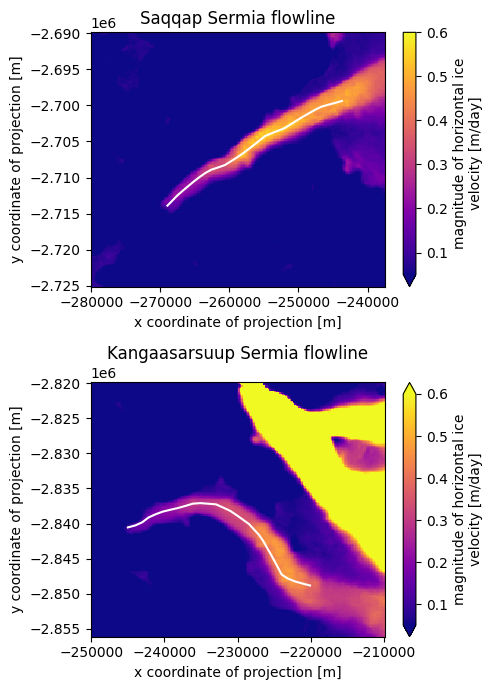

In [61]:
# Prime plotting space
fig, (ax1, ax2) = plt.subplots(2,
                               1,
                               figsize=(5,7))

# Plot mean velocities
saqqap_average.plot(ax=ax1,
                    cmap="plasma",
                    vmin=0.05,
                    vmax=0.6)

kangaasarsuup_average.plot(ax=ax2,
                        cmap="plasma",
                        vmin=0.05,
                        vmax=0.6)

# Overlay flowline point location
ax1.plot(x_even1, y_even1, c="white")
ax2.plot(x_even2, y_even2, c="white")

# Set plot titles and ensure correct spacing
ax1.set_title("Saqqap Sermia flowline")
ax2.set_title("Kangaasarsuup Sermia flowline")
plt.tight_layout()

# Show plot
plt.show()

From plotting, we can adjust our flowlines until we are happy that they effectively represent the central ice flow of Saqqap Sermia and Kangaasarsuup Sermia. Once we are ready, we can extract the horizontal velocity magnitude for each flowline point position at each time step in the dataset. We can extract these values using an interpolation, which will pick the nearest value to each flowline point.

In [66]:
# Extract velocities at Saqqap Sermia flowline
saqqap_flowline = ds_combined.interp(
    x=("points", x_even1),
    y=("points", y_even1),
    method="nearest"
)

# Preview the returned datasets
saqqap_flowline

<xarray.Dataset> Size: 64kB
Dimensions:                                  (time: 258, points: 30)
Coordinates:
  * time                                     (time) datetime64[ns] 2kB 2017-0...
    x                                        (points) float64 240B -2.69e+05 ...
    y                                        (points) float64 240B -2.714e+06...
Dimensions without coordinates: points
Data variables:
    land_ice_surface_velocity_magnitude      (time, points) float32 31kB 0.13...
    land_ice_surface_velocity_magnitude_std  (time, points) float32 31kB 0.07...
Attributes:
    Conventions:                     CF-1.5
    time_coverage_start:             2017-04-16
    time_coverage_end:               2017-05-09
    sensors_used:                    Sentinel-1A,Sentinel-1B
    institution:                     GEUS
    methods_used:                    Offset-tracking
    calibration_method:              None
    title:                           Greenland Ice Velocity from 2017-04-16 t...
    summary:                         Greenland Ice Velocity from Sentinel-1 o...
    product_version:                 1.0
    DODS.strlen:                     0
    DODS_EXTRA.Unlimited_Dimension:  time

In [67]:
# Extract velocities at Kangaasarsuup Sermia flowline
kangaasarsuup_flowline = ds_combined.interp(
    x=("points", x_even2),
    y=("points", y_even2),
    method="nearest"
)

# Preview the returned datasets
kangaasarsuup_flowline

<xarray.Dataset> Size: 64kB
Dimensions:                                  (time: 258, points: 30)
Coordinates:
  * time                                     (time) datetime64[ns] 2kB 2017-0...
    x                                        (points) float64 240B -2.45e+05 ...
    y                                        (points) float64 240B -2.841e+06...
Dimensions without coordinates: points
Data variables:
    land_ice_surface_velocity_magnitude      (time, points) float32 31kB 0.02...
    land_ice_surface_velocity_magnitude_std  (time, points) float32 31kB 0.04...
Attributes:
    Conventions:                     CF-1.5
    time_coverage_start:             2017-04-16
    time_coverage_end:               2017-05-09
    sensors_used:                    Sentinel-1A,Sentinel-1B
    institution:                     GEUS
    methods_used:                    Offset-tracking
    calibration_method:              None
    title:                           Greenland Ice Velocity from 2017-04-16 t...
    summary:                         Greenland Ice Velocity from Sentinel-1 o...
    product_version:                 1.0
    DODS.strlen:                     0
    DODS_EXTRA.Unlimited_Dimension:  time

## 4. Plot and compare ice velocities from two flowlines

Now we have our datasets, we can plot flowline ice velocity as a time-series to look at how flowline ice velocity changes over time. Let's create an average for each time step and then plot these, alongside the corresponding standard deviation as a source of uncertainty. To differentiate the two flowlines, we will plot Saqqap Sermia in blue, and Kangaasarsuup Sermia in red.

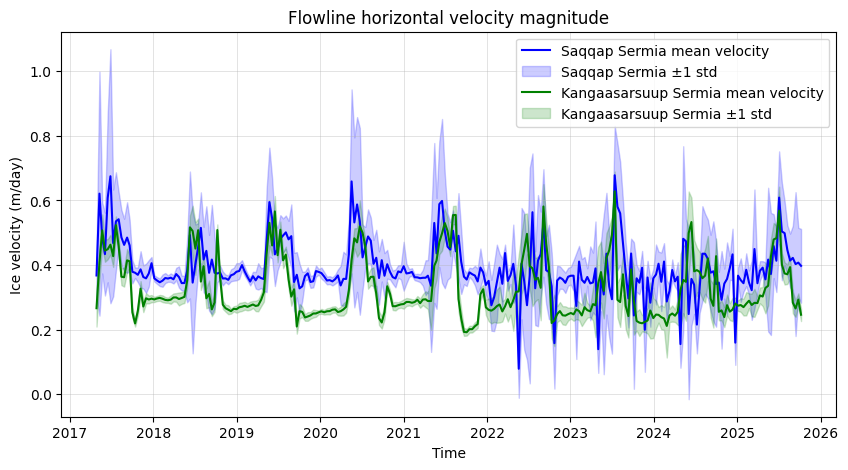

In [69]:
# Prime plotting area
plt.figure(figsize=(10,5))

# Plot mean and ±1 std along Saqqap Sermia flowline
flowline1_mean = saqqap_flowline["land_ice_surface_velocity_magnitude"].mean(dim="points")
flowline1_std_mean = saqqap_flowline["land_ice_surface_velocity_magnitude_std"].mean(dim="points")
# Plot average velocity with shaded std
plt.plot(flowline1_mean.time, flowline1_mean, label="Saqqap Sermia mean velocity", color="blue")
plt.fill_between(
    flowline1_mean.time,
    flowline1_mean - flowline1_std_mean,
    flowline1_mean + flowline1_std_mean,
    color="blue", alpha=0.2, label="Saqqap Sermia ±1 std"
)

# Plot mean and ±1 std along Kangaasarsuup Sermia flowline
flowline2_mean = kangaasarsuup_flowline["land_ice_surface_velocity_magnitude"].mean(dim="points")
flowline2_std_mean = kangaasarsuup_flowline["land_ice_surface_velocity_magnitude_std"].mean(dim="points")
# Plot average velocity with shaded std
plt.plot(flowline2_mean.time, flowline2_mean, label="Kangaasarsuup Sermia mean velocity", color="green")
plt.fill_between(
    flowline2_mean.time,
    flowline2_mean - flowline2_std_mean,
    flowline2_mean + flowline2_std_mean,
    color="green", alpha=0.2, label="Kangaasarsuup Sermia ±1 std"
)

# Format plot
plt.title("Flowline horizontal velocity magnitude")
plt.xlabel("Time")
plt.ylabel("Ice velocity (m/day)")
plt.grid()
plt.legend()
plt.show()

This figure reveals an interesting comparison between Saqqap Sermia (blue) and Kangaasarsuup Sermia (green). Both land-terminating glaciers exhibit pronounced seasonal velocity variability characterised by recurring summer accelerations and winter slowdowns, which is consistent with meltwater-enhanced basal sliding.

Saqqap Sermia maintains consistently higher mean velocities and greater variability than Kangaasarsuup Sermia, indicating stronger sensitivity to seasonal hydrological forcing. Kangaasarsuup Sermia behaves similarly, but with lower magnitude and lower variability.

Despite substantial interannual variability in peak summer velocities, neither glacier displays a strong long-term acceleration trend over 2017–2025, suggesting relatively stable dynamic conditions over this period.